# Simulate photonic lantern spectra

This notebook explains how to simulate photonic lantern's spectrum for given astronomical scenes.

### 1. Set up the mode-sorting device

First import necessary modules

In [1]:
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device

import hcipy as hc
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

For the mode-sorting device, we will use a 6-port photonic lantern. To set up the OTF matrix we can use `OTF.from_fiber_params` class method, which takes pupil grid, focal grid, and fiber parameters as inputs. Below are the parameters to set up a 6-port lantern.

In [2]:
# Define pupil grid (basically pixels)
ndim = 65 # this is enough for a 6-port PL
diameter = 10 # meters
pupil_grid = hc.make_pupil_grid(ndim, diameter)
ref_wavelength = 1.55e-6 # meters

# Define focal grid 
focal_plane_resolution = 1e-6 # meters. Make sure this samples LP modes enough but also not truncate the outer parts.
focal_length = 40 # meters (just an initial value. OTF.from_fiber_params will find an optimal focal ratio)
focal_grid = hc.make_pupil_grid(ndim, focal_plane_resolution * ndim)

# Define PL multimode entrance parameters (changing this would change the number of guided modes)
ncore = 1.444
nclad = 1.444 - 5.5e-3
rcore = 10e-6 # meters

# Telescope aperture (circular)
aperture = hc.make_circular_aperture(diameter)(pupil_grid)

In [3]:
otf = OTF.from_fiber_params(ncore, nclad, rcore, ref_wavelength,
                            focal_grid, pupil_grid, focal_length,
                            aperture, optimize_focal_length = False)

Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02']
Number of modes:  6


Now let's show how the focal-plane modes look like.

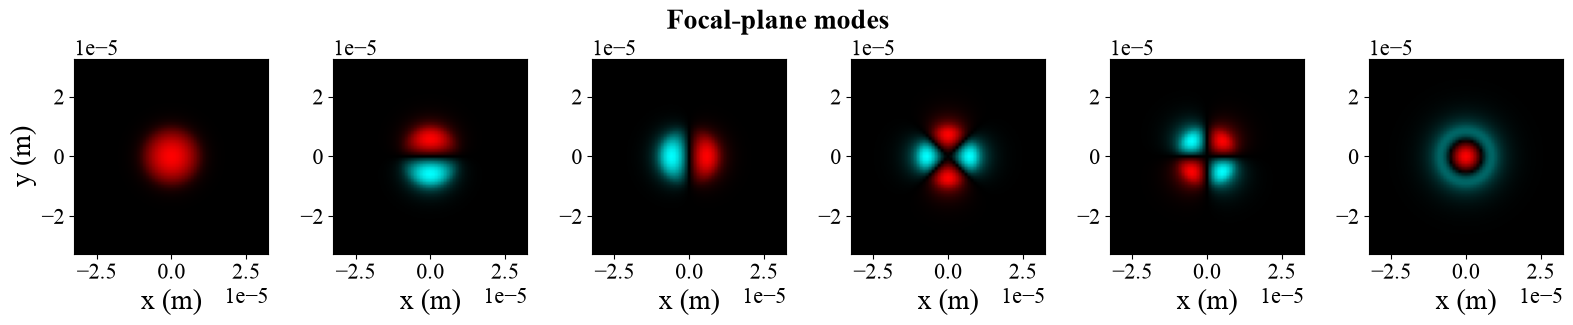

In [4]:
fig, axs = plt.subplots(ncols=6, figsize=(16,3))

for i in range(6):
    hc.imshow_field(otf.focal_modes[i], grid = focal_grid, ax=axs[i])
    axs[i].set_xlabel('x (m)')
fig.suptitle('Focal-plane modes')
axs[0].set_ylabel('y (m)')
fig.tight_layout()
plt.show()

This looks good (modes not out of the focal grid, also good enough sampling).

Now do `otf.compute()` to compute the OTF matrix.
Note that if the `ndim` is too large or the number of modes is big, this computation may be slow.

In [5]:
otf.compute()

Now set up the `Device` with a transfer matrix.

Let's assume 21 wavelength channels for our simulation.
The transfer matrix should have the dimension of (nwav X n_outputs X n_modes).

We will assume here a very narrow bandwidth, so that transfer matrix does not change with wavelength.

In [6]:
from PLsim.system.lantern import generate_unitary_matrix

nwav = 21
matrix  = generate_unitary_matrix(6)[np.newaxis,:,:].repeat(nwav, axis=0)

In [7]:
from PLsim.system.device import Device
device = Device(matrix)

Device initialized with:
  Lantern matrices: (21, 6, 6)
  PIC matrices: None
  Wavelengths: 21


### 2. Make the input scene

Define the `Scene` object to calculate mutual coherence functions, and the `SceneProjector` object that projects the mutual coherence functions onto the OTFs.

In [8]:
scene = Scene(pupil_grid, ref_wavelength)
scene_projector = SceneProjector(otf, scene)

Make an input scenes as a function of wavelength. Let's say we have binary stars, with one star having deep absorption line.

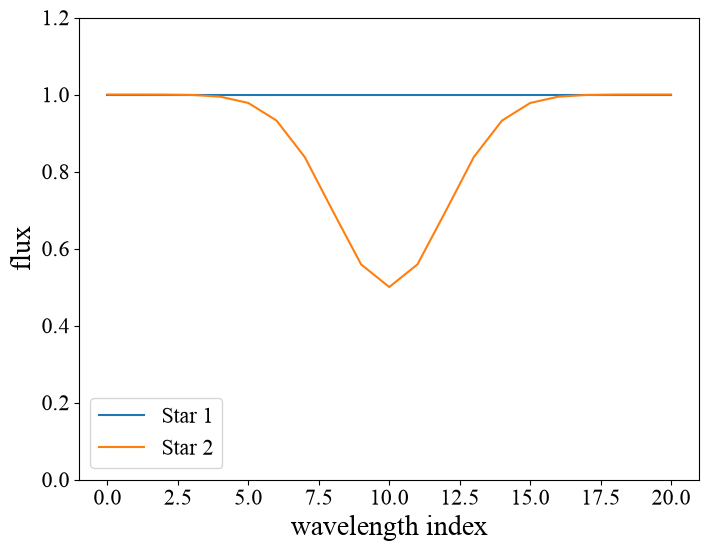

In [9]:
wavelength_inds = np.arange(nwav)

star1_spectrum = np.ones(nwav)
star2_spectrum = np.ones(nwav)

central_wavelength = nwav // 2
line_width = 2

star2_spectrum -= 0.5* np.exp(-0.5 * (wavelength_inds - central_wavelength)**2 / (line_width)**2)

fig = plt.figure(figsize=(8,6))
plt.plot(wavelength_inds, star1_spectrum, label='Star 1')
plt.plot(wavelength_inds, star2_spectrum, label='Star 2')
plt.ylim([0,1.2])
plt.legend()
plt.xlabel('wavelength index')
plt.ylabel('flux')
plt.show()

For binaries, simply compute responses for two positions and combine them.

In [10]:
star1_x, star1_y = 0, 0 # 0 mas, 0 mas (on-axis)
star2_x, star2_y = 15e-3/206265, 0 # 15 mas, 0 mas

# calculate responses for the two positions and scale by spectra
star1_projected = scene_projector.compute_point(star1_x, star1_y).repeat(nwav, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
star2_projected = scene_projector.compute_point(star2_x, star2_y).repeat(nwav, axis=2) * star2_spectrum[np.newaxis, np.newaxis]

combined = star1_projected + star2_projected

### 3. Simulate spectra

Now pass through the device!

In [11]:
# I need better treatment to avoid transpose
out_spectra = device.calculate_outputs(combined.transpose(2,0,1))

Plot the results

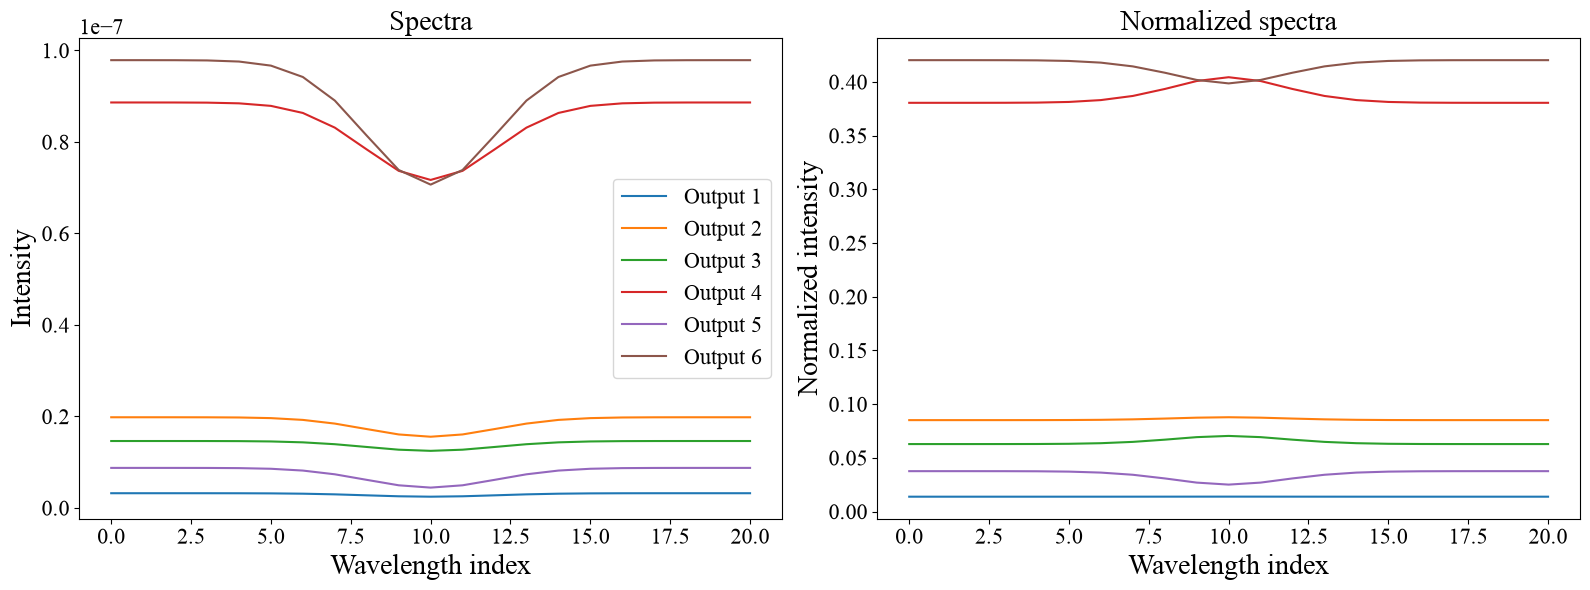

In [12]:
fig, axs = plt.subplots(ncols=2, figsize=(16,6))

for i in range(6):
    axs[0].plot(out_spectra[:,i], label=f'Output {i+1}')
    axs[1].plot(out_spectra[:,i]/np.sum(out_spectra,axis=1))

axs[0].set_title('Spectra')
axs[1].set_title('Normalized spectra')
axs[0].set_xlabel('Wavelength index')
axs[1].set_xlabel('Wavelength index')
axs[0].set_ylabel('Intensity')
axs[1].set_ylabel('Normalized intensity')
axs[0].legend()
fig.tight_layout()
plt.show()

### 4. More complex scenes

One may want to simulate more complex scenes. For this case, it is useful to generate a 2D grid of responses, then synthesize it to simulate any image.

In [13]:
fov = 50e-3 / 206265 # radians (100 mas)
ngrid = 64 # number of grid points along one axis. Odd number to have a center point. Increasing this significantly increases computation time.
out_grid = scene_projector.compute_point_grid(fov, ngrid)

I have provided `disk_images.npy` that simulates Keplerian disk line emission around a star that has flat spectrum. 

In [14]:
images = np.load('disk_images.npy')
vgrid = np.linspace(-300, 300, nwav) # km/s, used for simulation of the images

This is how the images look like

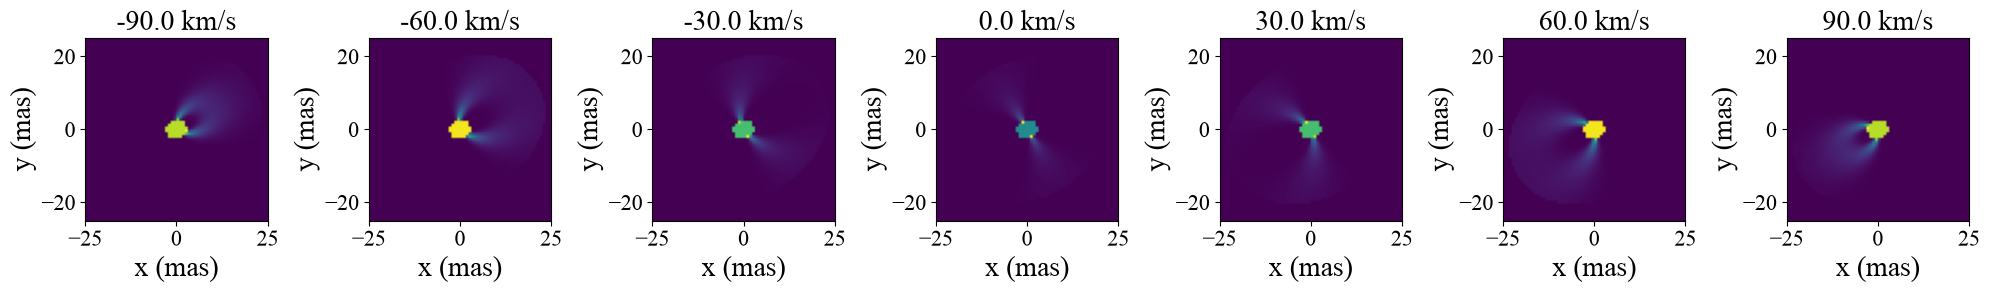

In [15]:
show_indices = np.arange(10-3, 10+4, 1)
fig, axs = plt.subplots(ncols=len(show_indices), figsize=(20,8))
for i, ind in enumerate(show_indices):
    axs[i].imshow(images[ind], origin='lower', extent=(-fov/2*206265e3, fov/2*206265e3, -fov/2*206265e3, fov/2*206265e3))
    axs[i].set_title(f'{vgrid[ind]:.1f} km/s')
    axs[i].set_xlabel('x (mas)')
    axs[i].set_ylabel('y (mas)')
fig.tight_layout()
plt.show()

Now simulate the spectra

In [16]:
disk_outs = (device.calculate_outputs(scene_projector.compute_scene_from_image(images)))

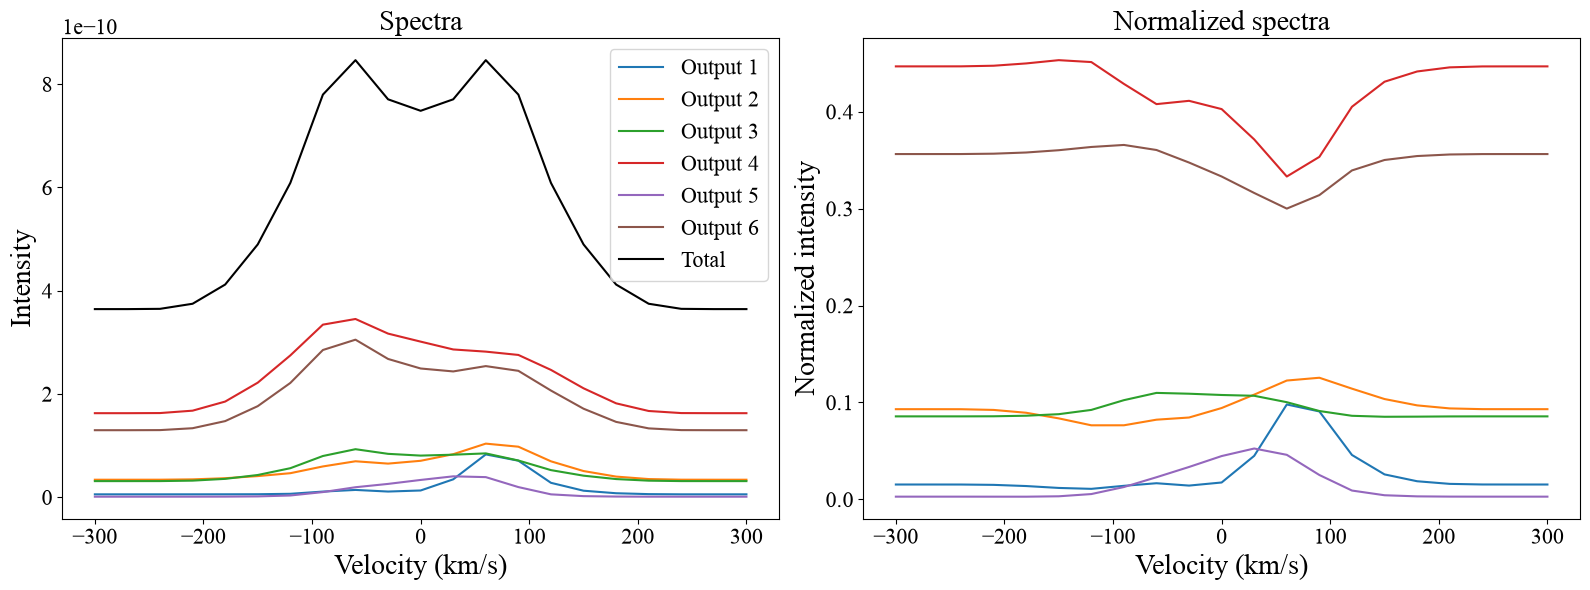

In [17]:
fig, axs = plt.subplots(ncols=2, figsize=(16,6))
for i in range(6):
    axs[0].plot(vgrid, disk_outs[:,i], label=f'Output {i+1}')
    axs[1].plot(vgrid, disk_outs[:,i]/np.sum(disk_outs,axis=1))

axs[0].plot(vgrid, np.sum(disk_outs, axis=1), label='Total', color='k')
axs[0].set_title('Spectra')
axs[1].set_title('Normalized spectra')
axs[0].set_xlabel('Velocity (km/s)')
axs[1].set_xlabel('Velocity (km/s)')
axs[0].set_ylabel('Intensity')
axs[1].set_ylabel('Normalized intensity')
axs[0].legend()
fig.tight_layout()
plt.show()

### 5. Observe with a different lantern

Let's try observing the same image with a higher mode count lantern - a 19-port one.

In [18]:
# The only change is the size of the fiber core. This gives 19 guided modes.
rcore2 = 16.5e-6 # meters

In [19]:
otf2 = OTF.from_fiber_params(ncore, nclad, rcore2, ref_wavelength,
                            focal_grid, pupil_grid, focal_length,
                            aperture, optimize_focal_length = False)

Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02', 'LP31a', 'LP31b', 'LP12a', 'LP12b', 'LP41a', 'LP41b', 'LP22a', 'LP22b', 'LP03', 'LP51a', 'LP51b', 'LP32a', 'LP32b']
Number of modes:  19


In [20]:
otf2.compute()

Define 19x19 unitary matrix to simulate standard 19-port lantern.

In [21]:
matrix2  = generate_unitary_matrix(19)[np.newaxis,:,:].repeat(nwav, axis=0)

Now this is our new device.

In [22]:
device2 = Device(matrix2)

Device initialized with:
  Lantern matrices: (21, 19, 19)
  PIC matrices: None
  Wavelengths: 21


We need to compute the scene projector again.

In [23]:
scene_projector2 = SceneProjector(otf2, scene)

Also the point-source responses on 2d grid. This takes longer than before; 6 seconds on my laptop.

In [24]:
out_grid2 = scene_projector2.compute_point_grid(fov, ngrid)

Let's now simulate the output intensities!

In [25]:
disk_outs2 = (device2.calculate_outputs(scene_projector2.compute_scene_from_image(images)))

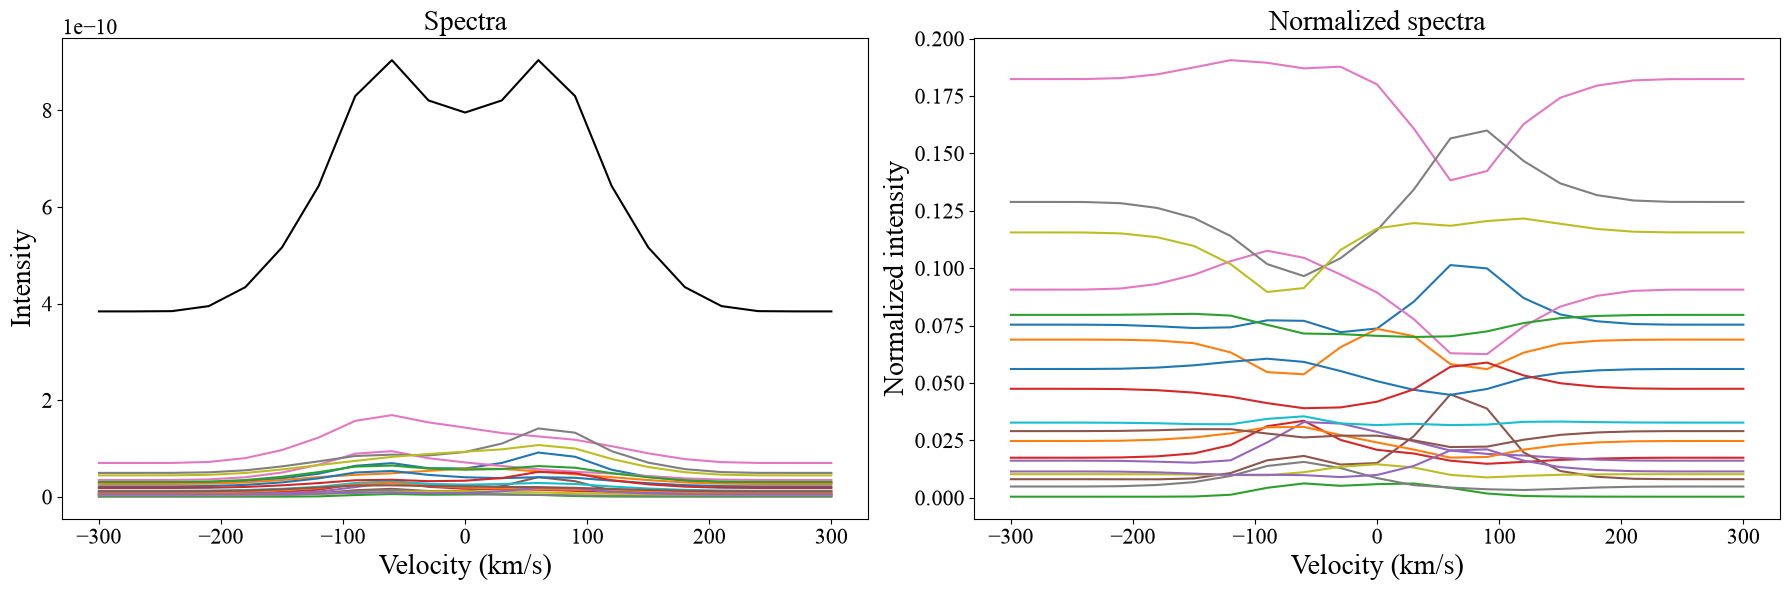

In [26]:
fig, axs = plt.subplots(ncols=2, figsize=(18, 6))
for i in range(19):
    axs[0].plot(vgrid, disk_outs2[:,i], label=f'Output {i+1}')
    axs[1].plot(vgrid, disk_outs2[:,i]/np.sum(disk_outs2,axis=1))

axs[0].plot(vgrid, np.sum(disk_outs2, axis=1), label='Total', color='k')
axs[0].set_title('Spectra')
axs[1].set_title('Normalized spectra')
axs[0].set_xlabel('Velocity (km/s)')
axs[1].set_xlabel('Velocity (km/s)')
axs[0].set_ylabel('Intensity')
axs[1].set_ylabel('Normalized intensity')
# axs[0].legend()
fig.tight_layout()
plt.show()